# UIT-VSFC — Từ khảo sát dữ liệu đến so sánh 3 thuật toán Baseline

Notebook tổng hợp: **EDA → phân loại cảm xúc → phân loại chủ đề → biểu đồ so sánh**.
Chạy lần lượt từng ô từ trên xuống dưới để tự tạo bảng kết quả và biểu đồ.
Để tái lập: chọn Python `student_feedback/.venv/Scripts/python.exe`, rồi **Restart Kernel → Run All**.
Cần dữ liệu `data/raw`, `data/manifest.json` và các thư viện dự án.

**Mối liên hệ với các file cũ:** `01_eda` khảo sát dữ liệu; `02_sentiment` và
`03_topic` train/đánh giá; `demo_validation_chart.py` vẽ Macro-F1 validation.
Các thư mục `outputs/validation-demo-*` là kết quả của từng lần chạy script đó.
Notebook này tính lại số liệu Baseline theo cùng các module và ghép thành một báo cáo.
`04_macro_f1_model_comparison` dùng các pipeline đã lưu, trong đó SVM được cải tiến;
điểm của notebook đó có thể khác Baseline ở đây.

**Quy tắc:** giữ nguyên split chính thức; TF-IDF và classifier chỉ fit trên train;
chọn model theo Macro-F1 validation; test chỉ để báo cáo sau khi chọn.
Không dùng các điểm này để kết luận độ chính xác của nhãn mở rộng trên web.
Mặc định chỉ hiển thị kết quả, không ghi file phụ. Đặt `SAVE_OUTPUTS = True` ở ô thiết lập nếu muốn lưu vào một thư mục kết quả mới.

**Bắt đầu:** chạy ô kiểm tra thư viện dưới đây. Ô này chỉ cài các thư viện còn thiếu vào đúng Python của kernel hiện tại; cần kết nối mạng nếu phải cài. Sau đó chạy tiếp từng ô bằng **Shift+Enter**. Khi chạy lại toàn bộ, chọn **Restart Kernel** trước.

In [ ]:
# Bước 0: kiểm tra và cài thư viện còn thiếu trong kernel hiện tại.
import sys
import subprocess
import importlib.util

required = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "joblib": "joblib", "sklearn": "scikit-learn",
}
missing = [package for module, package in required.items()
           if importlib.util.find_spec(module) is None]
print("Python của kernel:", sys.executable)
if missing:
    print("Cài thư viện còn thiếu:", ", ".join(missing), flush=True)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()
print("Đủ thư viện. Tiếp tục chạy ô thiết lập bên dưới.")

Python của kernel: c:\Users\DELL\AppData\Local\Programs\Python\Python313\python.exe
Đủ thư viện. Tiếp tục chạy ô thiết lập bên dưới.


In [2]:
from pathlib import Path
from datetime import datetime
import sys, json, io, base64, platform, os
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import ConfusionMatrixDisplay

try:
    display
except NameError:
    def display(value, raw=False):
        print("Ảnh đã lưu trong thư mục kết quả." if raw else value)

candidates = [p / s for p in [Path.cwd(), *Path.cwd().parents]
              for s in ("", "student_feedback", "student-feedback-ai/student_feedback")]
ROOT = next((p.resolve() for p in candidates
             if (p / "src/feedback_ai").is_dir() and (p / "data/raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ workspace hoặc thư mục student_feedback có data/raw.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from feedback_ai.data.loader import load_dataset
from feedback_ai.data.preprocessing import normalize_text
from feedback_ai.common.labels import SENTIMENT_LABELS, TOPIC_LABELS
from feedback_ai.evaluation.topic import verify_dataset_manifest
from feedback_ai.training import sentiment, topic
from feedback_ai.evaluation import sentiment as sentiment_metrics, topic as topic_metrics

manifest_hash = verify_dataset_manifest(ROOT / "data/raw", ROOT / "data/manifest.json")
frames = load_dataset(ROOT / "data/raw")
OUTPUT_ROOT = Path(os.environ.get("BASELINE_NOTEBOOK_OUTPUT", str(ROOT / "outputs")))
RUN = OUTPUT_ROOT / ("baseline-notebook-" + datetime.now().strftime("%Y%m%d-%H%M%S-%f"))
SAVE_OUTPUTS = False  # Đổi thành True nếu muốn lưu CSV, ảnh và model.
if SAVE_OUTPUTS:
    RUN.mkdir(parents=True, exist_ok=False)
ALGORITHMS = ("nb", "logistic_regression", "linear_svm")
NAMES = {"nb": "Naive Bayes", "logistic_regression": "Logistic Regression", "linear_svm": "Linear SVM"}
LABELS = {"sentiment": list(SENTIMENT_LABELS), "topic": list(TOPIC_LABELS)}
results, fitted = {}, {}

def save_json(name, payload):
    if SAVE_OUTPUTS:
        (RUN / name).write_text(json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8")

def save_csv(frame, filename, **kwargs):
    if SAVE_OUTPUTS:
        frame.to_csv(RUN / filename, encoding="utf-8-sig", **kwargs)

def show_figure(fig, filename):
    fig.tight_layout()
    if SAVE_OUTPUTS:
        fig.savefig(RUN / filename, dpi=160, bbox_inches="tight")
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110, bbox_inches="tight")
    display({"image/png": base64.b64encode(buffer.getvalue()).decode("ascii")}, raw=True)
    plt.close(fig)

environment = {"python": platform.python_version(),
               "packages": {p: version(p) for p in ("numpy", "pandas", "matplotlib", "scikit-learn", "joblib")},
               "dataset_manifest_sha256": manifest_hash}
save_json("environment.json", environment)
print("Python:", sys.executable)
print("Lưu file:", RUN if SAVE_OUTPUTS else "Tắt — kết quả hiển thị trực tiếp trong notebook")
print("SHA-256 manifest:", manifest_hash)
display(pd.Series(environment["packages"], name="Phiên bản").to_frame())

Python: c:\Users\DELL\AppData\Local\Programs\Python\Python313\python.exe
Lưu file: Tắt — kết quả hiển thị trực tiếp trong notebook
SHA-256 manifest: 100b82c7670114c822cb78e2aae153586fad5f625697ca64a1167bb659c2177e


,Phiên bản
numpy,2.4.0
pandas,2.3.3
matplotlib,3.11.2
scikit-learn,1.9.1
joblib,1.6.0


## 1. Khảo sát dữ liệu (EDA)

UIT-VSFC có hai bộ nhãn: cảm xúc (`negative`, `neutral`, `positive`) và chủ đề
(`lecturer`, `curriculum`, `facility`, `other`). Kiểm tra số dòng, dữ liệu trống,
độ dài văn bản và phân bố nhãn của từng split. Giữ nguyên dữ liệu và split;
các thống kê test chỉ mô tả dữ liệu, không dùng để chọn model hoặc thay tham số.

In [3]:
overview = pd.DataFrame({split: {
    "Số câu": len(frame), "Văn bản null": int(frame.text.isna().sum()),
    "Văn bản trống": int(frame.text.str.strip().eq("").sum()),
    "Văn bản trùng trong split": int(frame.text.duplicated().sum()),
    "Độ dài trung bình (ký tự)": round(frame.text.str.len().mean(), 2),
    "Độ dài lớn nhất": int(frame.text.str.len().max())
} for split, frame in frames.items()}).T
display(overview)
save_csv(overview, "eda_overview.csv")
display(frames["train"][["text", "sentiment", "topic"]].head(8))
lengths = pd.DataFrame({s: f.text.str.len().describe() for s, f in frames.items()})
display(lengths.round(2))
save_csv(lengths, "text_length.csv")

,Số câu,Văn bản null,Văn bản trống,Văn bản trùng trong split,Độ dài trung bình (ký tự),Độ dài lớn nhất
train,11426.0,0.0,0.0,1.0,59.08,660.0
validation,1583.0,0.0,0.0,0.0,56.36,718.0
test,3166.0,0.0,0.0,0.0,58.84,411.0


,text,sentiment,topic
0,slide giáo trình đầy đủ .,positive,curriculum
1,"nhiệt tình giảng dạy , gần gũi với sinh viên .",positive,lecturer
2,đi học đầy đủ full điểm chuyên cần .,negative,curriculum
3,chưa áp dụng công nghệ thông tin và các thiết ...,negative,lecturer
4,"thầy giảng bài hay , có nhiều bài tập ví dụ ng...",positive,lecturer
5,"giảng viên đảm bảo thời gian lên lớp , tích cự...",positive,lecturer
6,"em sẽ nợ môn này , nhưng em sẽ học lại ở các h...",neutral,other
7,"thời lượng học quá dài , không đảm bảo tiếp th...",negative,curriculum


,train,validation,test
count,11426.00,1583.00,3166.00
mean,59.08,56.36,58.84
std,43.09,42.77,44.13
min,4.00,4.00,4.00
25%,31.00,31.00,30.00
50%,47.00,45.00,46.00
75%,73.00,69.00,73.00
max,660.00,718.00,411.00


Phân bố nhãn: sentiment


,train,validation,test
sentiment,,,
negative,5325,705,1409
neutral,458,73,167
positive,5643,805,1590


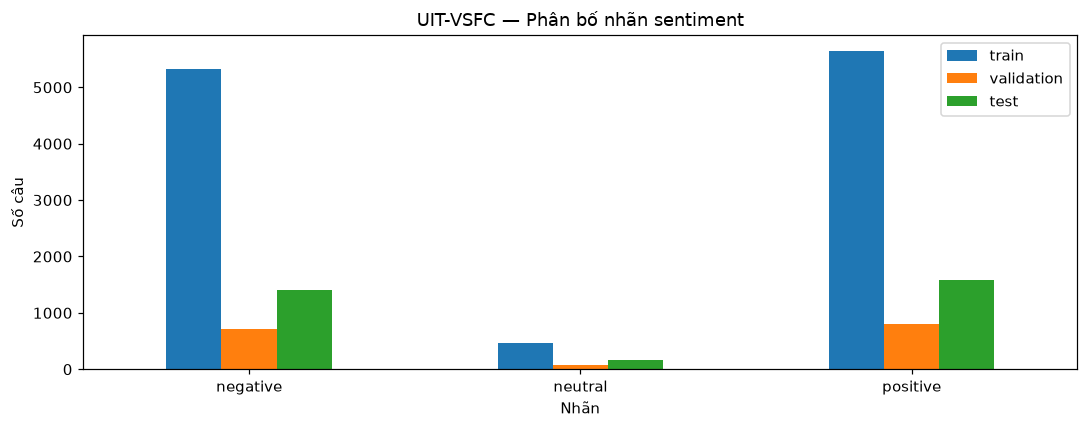

Phân bố nhãn: topic


,train,validation,test
topic,,,
lecturer,8166,1151,2290
curriculum,2201,267,572
facility,497,70,145
other,562,95,159


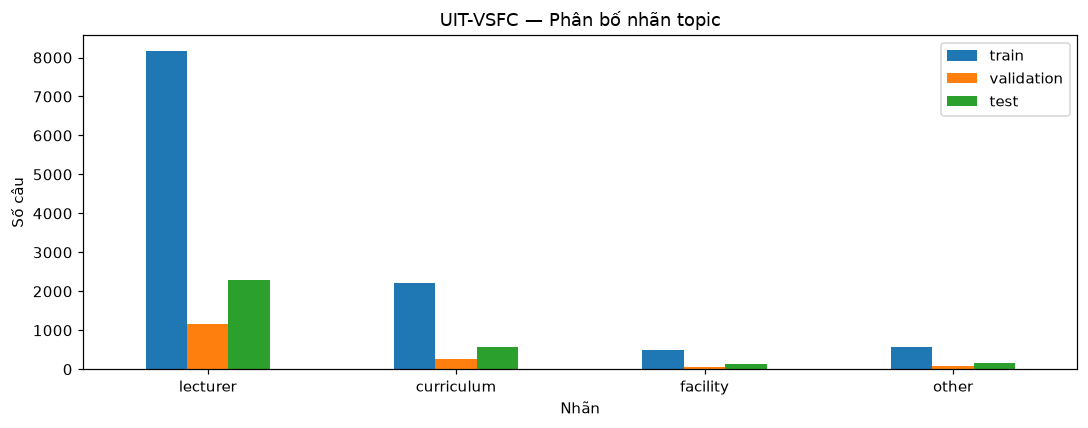

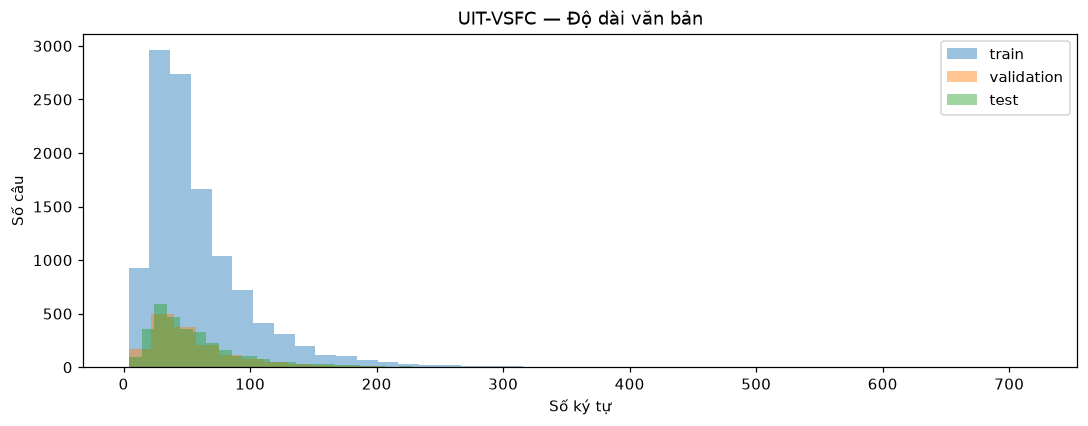

In [4]:
for task, labels in LABELS.items():
    counts = pd.DataFrame({s: f[task].value_counts().reindex(labels, fill_value=0)
                           for s, f in frames.items()})
    print("Phân bố nhãn:", task)
    display(counts)
    save_csv(counts, f"eda_{task}_counts.csv")
    ax = counts.plot.bar(figsize=(10, 4), rot=0)
    ax.set(title=f"UIT-VSFC — Phân bố nhãn {task}", ylabel="Số câu", xlabel="Nhãn")
    show_figure(ax.figure, f"eda_{task}.png")
fig, ax = plt.subplots(figsize=(10, 4))
for split, frame in frames.items():
    ax.hist(frame.text.str.len(), bins=40, alpha=0.45, label=split)
ax.set(title="UIT-VSFC — Độ dài văn bản", xlabel="Số ký tự", ylabel="Số câu")
ax.legend()
show_figure(fig, "eda_text_length.png")

## 2. Cách huấn luyện và đánh giá chung

Văn bản được chuẩn hóa Unicode NFC, chuyển chữ thường và gộp khoảng trắng.
TF-IDF dùng word unigram/bigram, `min_df=2`, `sublinear_tf=True`, chuẩn L2.
Ba classifier: Multinomial Naive Bayes (`alpha=1`), Logistic Regression (`C=1`)
và Linear SVM (`C=1`), theo cấu hình Baseline trong mã nguồn dự án.

**Accuracy** là tỷ lệ dự đoán đúng. Với mỗi lớp: Precision = TP/(TP+FP),
Recall = TP/(TP+FN), F1 = 2PR/(P+R). **Macro-F1** là trung bình F1 của các lớp,
mỗi lớp có trọng số ngang nhau; phép chia có mẫu số 0 cho kết quả 0.
Macro-F1 giúp nhìn rõ hiệu quả với các lớp ít dữ liệu hơn trong EDA.

Hàm dưới train trên train, khóa lựa chọn bằng validation rồi mới đánh giá test.
Nếu Macro-F1 chênh không quá 1e-6, dùng validation accuracy rồi thứ tự NB → LR → SVM.
Lưu pipeline được chọn, cấu hình, metric và dự đoán để truy vết.

In [5]:
def run_task(task, trainer, evaluator):
    print(f"Đang train 3 thuật toán: {task}", flush=True)
    models = trainer.train_models(frames["train"])
    selection = trainer.select_model(models, frames["validation"])
    metrics = {split: evaluator.evaluate_models(models, frames[split])
               for split in ("validation", "test")}
    configuration = {name: topic.pipeline_parameters(model) if task == "topic" else
                     {"tfidf": sentiment.TFIDF_PARAMS,
                      "classifier": {"name": name, **sentiment.CLF_PARAMS[name]}}
                     for name, model in models.items()}
    payload = {"task": task, "selection": selection, **metrics,
               "dataset_manifest_sha256": manifest_hash, "configuration": configuration,
               "split_sizes": {s: len(f) for s, f in frames.items()}}
    results[task], fitted[task] = payload, models
    save_json(f"{task}_comparison.json", payload)
    if SAVE_OUTPUTS:
        joblib.dump(models[selection["algorithm"]], RUN / f"{task}_pipeline.joblib")
    for split in ("validation", "test"):
        evidence = frames[split][["id", "text", task]].copy()
        for name, model in models.items():
            evidence[name] = model.predict(frames[split].text.tolist())
        save_csv(evidence, f"{task}_{split}_predictions.csv", index=False)
    table = pd.DataFrame([
        {"Thuật toán": NAMES[name], "Split": split,
         "Accuracy": m["accuracy"], "Macro-Precision": m["macro_precision"],
         "Macro-Recall": m["macro_recall"], "Macro-F1": m["macro_f1"]}
        for split in ("validation", "test") for name, m in metrics[split].items()])
    display(table.round(6))
    save_csv(table, f"{task}_scores.csv", index=False)
    print("Chọn bằng validation:", NAMES[selection["algorithm"]])
    return payload

def show_details(task):
    payload = results[task]
    for split in ("validation", "test"):
        print(f"{task} / {split}: Precision, Recall, F1 và Support từng lớp")
        per_class = pd.DataFrame([
            {"algorithm": NAMES[name], **row}
            for name in ALGORITHMS for row in payload[split][name]["per_class"]])
        display(per_class.round(6))
        save_csv(per_class, f"{task}_{split}_per_class.csv", index=False)
        fig, axes = plt.subplots(1, 3, figsize=(17, 4))
        for ax, name in zip(axes, ALGORITHMS):
            metric = payload[split][name]
            ConfusionMatrixDisplay(np.array(metric["confusion_matrix"]),
                                   display_labels=metric["label_order"]).plot(
                ax=ax, colorbar=False, xticks_rotation=30)
            ax.set(title=NAMES[name], xlabel="Dự đoán", ylabel="Nhãn thật")
        fig.suptitle(f"{task} — {split} (hàng: nhãn thật; cột: dự đoán)")
        show_figure(fig, f"{task}_{split}_confusion_matrices.png")
    winner = payload["selection"]["algorithm"]
    score = payload["test"][winner]
    print(f"Model đã chọn: {NAMES[winner]}; test accuracy={score['accuracy']:.2%}, "
          f"test Macro-F1={score['macro_f1']:.2%}.")

## 3. Huấn luyện và đánh giá phân loại cảm xúc

Ba nhãn: tiêu cực, trung tính, tích cực. Bảng dưới báo cáo validation và test cho cả 3 thuật toán.

In [6]:
sentiment_result = run_task("sentiment", sentiment, sentiment_metrics)

Đang train 3 thuật toán: sentiment


,Thuật toán,Split,Accuracy,Macro-Precision,Macro-Recall,Macro-F1
0,Naive Bayes,validation,0.873026,0.582215,0.611139,0.595527
1,Logistic Regression,validation,0.907770,0.877831,0.671929,0.688945
2,Linear SVM,validation,0.914719,0.849978,0.721628,0.752966
3,Naive Bayes,test,0.857233,0.572207,0.604441,0.586950
4,Logistic Regression,test,0.889766,0.823527,0.646977,0.648432
5,Linear SVM,test,0.897031,0.804905,0.685335,0.705104


Chọn bằng validation: Linear SVM


sentiment / validation: Precision, Recall, F1 và Support từng lớp


,algorithm,label,precision,recall,f1,support
0,Naive Bayes,negative,0.830615,0.939007,0.881491,705
1,Naive Bayes,neutral,0.000000,0.000000,0.000000,73
2,Naive Bayes,positive,0.916031,0.894410,0.905091,805
3,Logistic Regression,negative,0.884363,0.954610,0.918145,705
4,Logistic Regression,neutral,0.818182,0.123288,0.214286,73
5,Logistic Regression,positive,0.930949,0.937888,0.934406,805
6,Linear SVM,negative,0.909589,0.941844,0.925436,705
7,Linear SVM,neutral,0.714286,0.273973,0.396040,73
8,Linear SVM,positive,0.926061,0.949068,0.937423,805


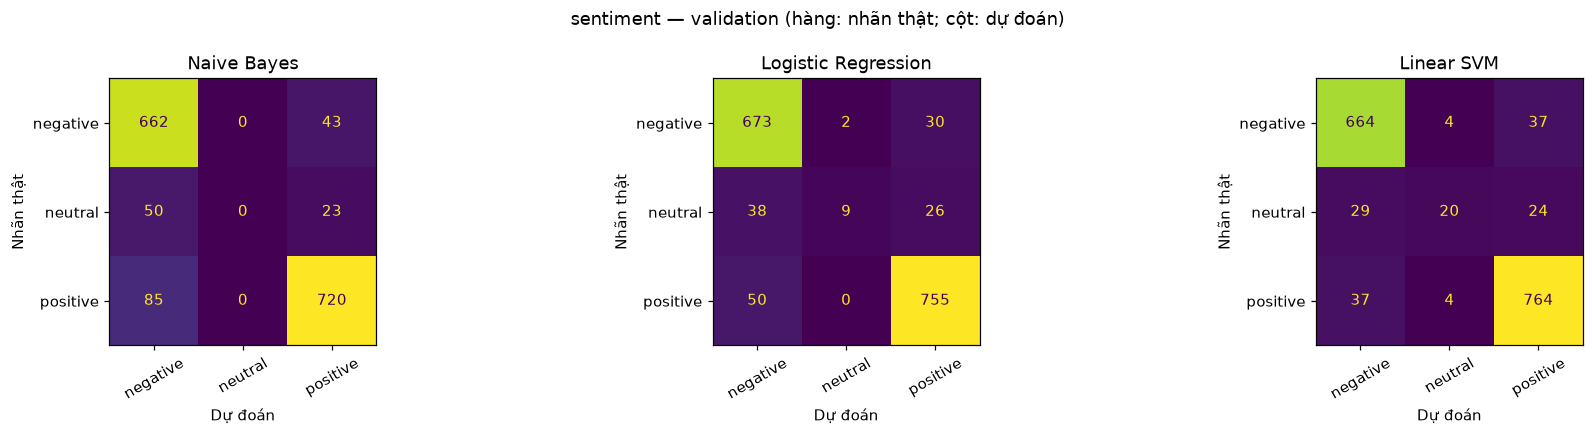

sentiment / test: Precision, Recall, F1 và Support từng lớp


,algorithm,label,precision,recall,f1,support
0,Naive Bayes,negative,0.816491,0.934705,0.871608,1409
1,Naive Bayes,neutral,0.000000,0.000000,0.000000,167
2,Naive Bayes,positive,0.900129,0.878616,0.889243,1590
3,Logistic Regression,negative,0.850998,0.968772,0.906074,1409
4,Logistic Regression,neutral,0.687500,0.065868,0.120219,167
5,Logistic Regression,positive,0.932083,0.906289,0.919005,1590
6,Linear SVM,negative,0.875486,0.958126,0.914944,1409
7,Linear SVM,neutral,0.612245,0.179641,0.277778,167
8,Linear SVM,positive,0.926984,0.918239,0.922591,1590


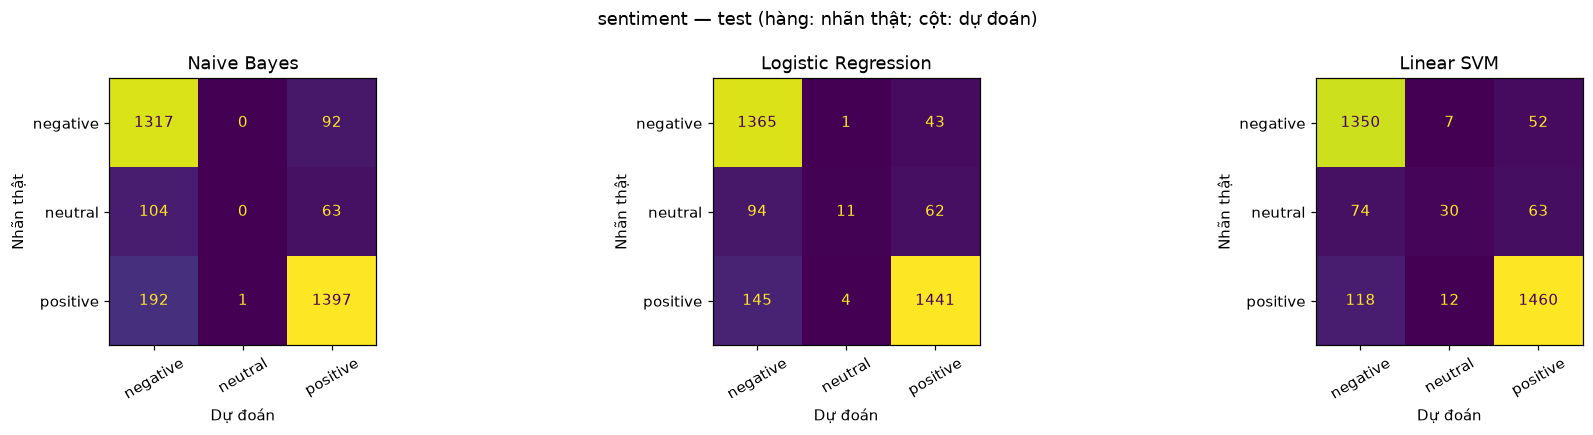

Model đã chọn: Linear SVM; test accuracy=89.70%, test Macro-F1=70.51%.


In [7]:
show_details("sentiment")

## 4. Huấn luyện và đánh giá phân loại chủ đề

Bốn nhãn: giảng viên, chương trình đào tạo, cơ sở vật chất, khác. Áp dụng cùng nguyên tắc fit và chọn model như phần cảm xúc.

In [8]:
topic_result = run_task("topic", topic, topic_metrics)

Đang train 3 thuật toán: topic


,Thuật toán,Split,Accuracy,Macro-Precision,Macro-Recall,Macro-F1
0,Naive Bayes,validation,0.818067,0.626486,0.481143,0.522547
1,Logistic Regression,validation,0.864814,0.826921,0.635575,0.682239
2,Linear SVM,validation,0.879975,0.810247,0.737291,0.754173
3,Naive Bayes,test,0.819646,0.886575,0.500193,0.545789
4,Logistic Regression,test,0.859760,0.810086,0.658390,0.698190
5,Linear SVM,test,0.861655,0.780204,0.713869,0.735382


Chọn bằng validation: Linear SVM


topic / validation: Precision, Recall, F1 và Support từng lớp


,algorithm,label,precision,recall,f1,support
0,Naive Bayes,lecturer,0.830508,0.979149,0.898724,1151
1,Naive Bayes,curriculum,0.707692,0.516854,0.597403,267
2,Naive Bayes,facility,0.967742,0.428571,0.594059,70
3,Naive Bayes,other,0.000000,0.000000,0.000000,95
4,Logistic Regression,lecturer,0.895547,0.960904,0.927075,1151
5,Logistic Regression,curriculum,0.724638,0.749064,0.736648,267
6,Logistic Regression,facility,0.937500,0.642857,0.762712,70
7,Logistic Regression,other,0.750000,0.189474,0.302521,95
8,Linear SVM,lecturer,0.920541,0.946134,0.933162,1151
9,Linear SVM,curriculum,0.736111,0.794007,0.763964,267


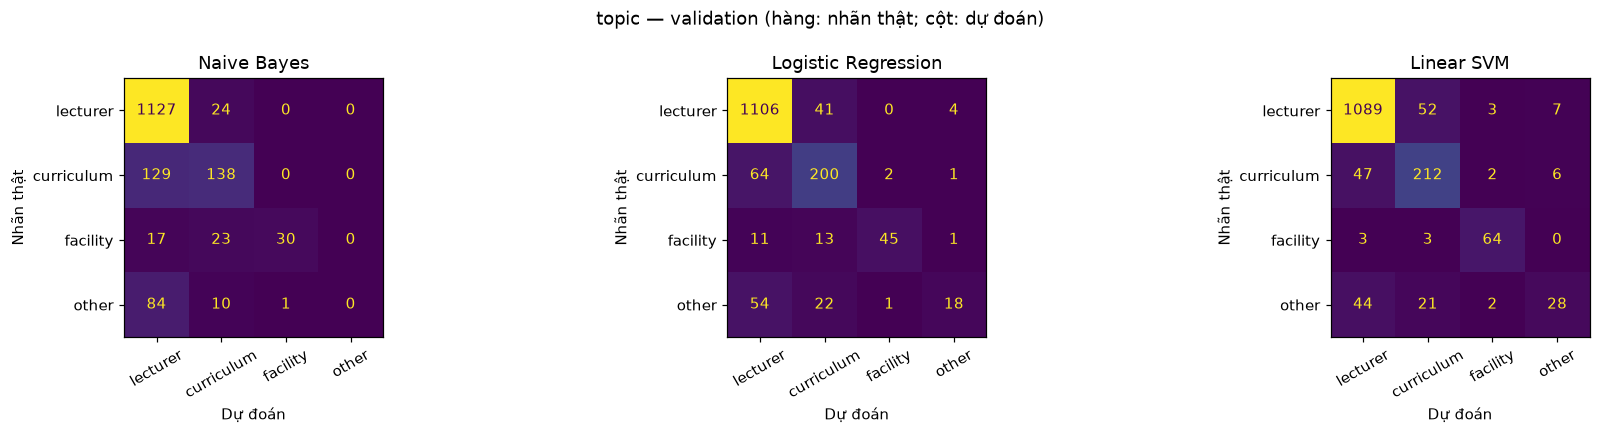

topic / test: Precision, Recall, F1 và Support từng lớp


,algorithm,label,precision,recall,f1,support
0,Naive Bayes,lecturer,0.826055,0.982969,0.897707,2290
1,Naive Bayes,curriculum,0.732591,0.459790,0.564984,572
2,Naive Bayes,facility,0.987654,0.551724,0.707965,145
3,Naive Bayes,other,1.000000,0.006289,0.012500,159
4,Logistic Regression,lecturer,0.890159,0.951965,0.920025,2290
5,Logistic Regression,curriculum,0.716094,0.692308,0.704000,572
6,Logistic Regression,facility,0.975000,0.806897,0.883019,145
7,Logistic Regression,other,0.659091,0.182390,0.285714,159
8,Linear SVM,lecturer,0.909593,0.935808,0.922514,2290
9,Linear SVM,curriculum,0.691126,0.708042,0.699482,572


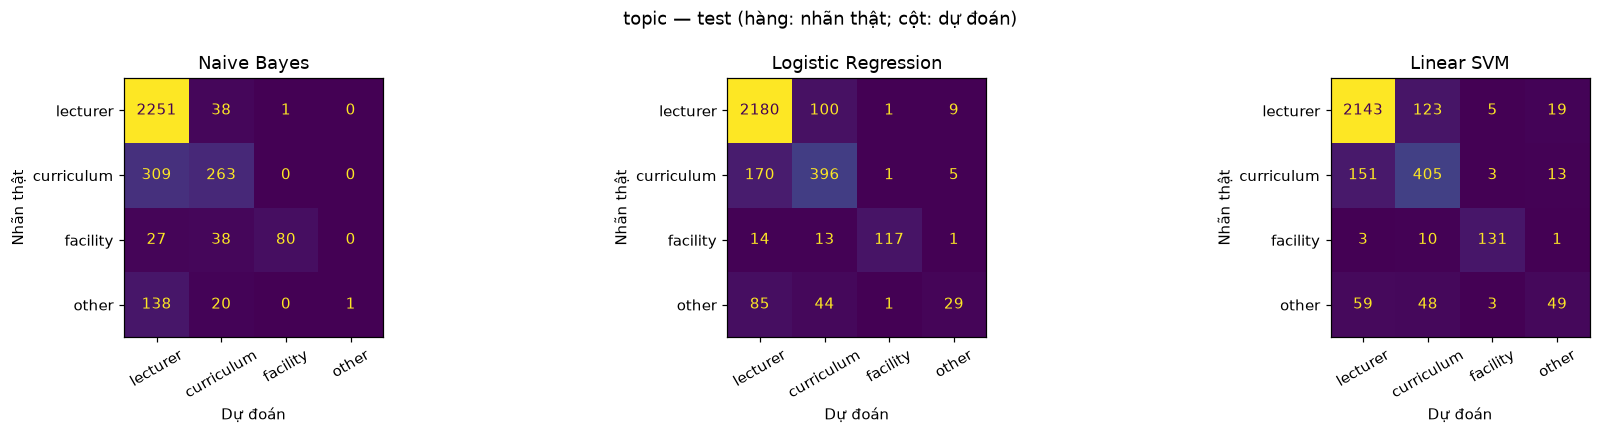

Model đã chọn: Linear SVM; test accuracy=86.17%, test Macro-F1=73.54%.


In [9]:
show_details("topic")

## 5. Biểu đồ so sánh 3 thuật toán trên UIT-VSFC (Baseline)

Biểu đồ dùng **Macro-F1 trên validation (%)**, giống `demo_validation_chart.py`.
Mỗi thuật toán có hai cột: cảm xúc và chủ đề. Số liệu lấy trực tiếp từ kết quả
vừa tính ở phần 3–4; không nhập tay hoặc trộn với pipeline SVM cải tiến.
Bảng tổng hợp có thêm test để báo cáo, nhưng cột test không tham gia chọn model.

,task,algorithm,validation_macro_f1,validation_accuracy,test_macro_f1,test_accuracy
0,sentiment,nb,0.595527,0.873026,0.586950,0.857233
1,sentiment,logistic_regression,0.688945,0.907770,0.648432,0.889766
2,sentiment,linear_svm,0.752966,0.914719,0.705104,0.897031
3,topic,nb,0.522547,0.818067,0.545789,0.819646
4,topic,logistic_regression,0.682239,0.864814,0.698190,0.859760
5,topic,linear_svm,0.754173,0.879975,0.735382,0.861655


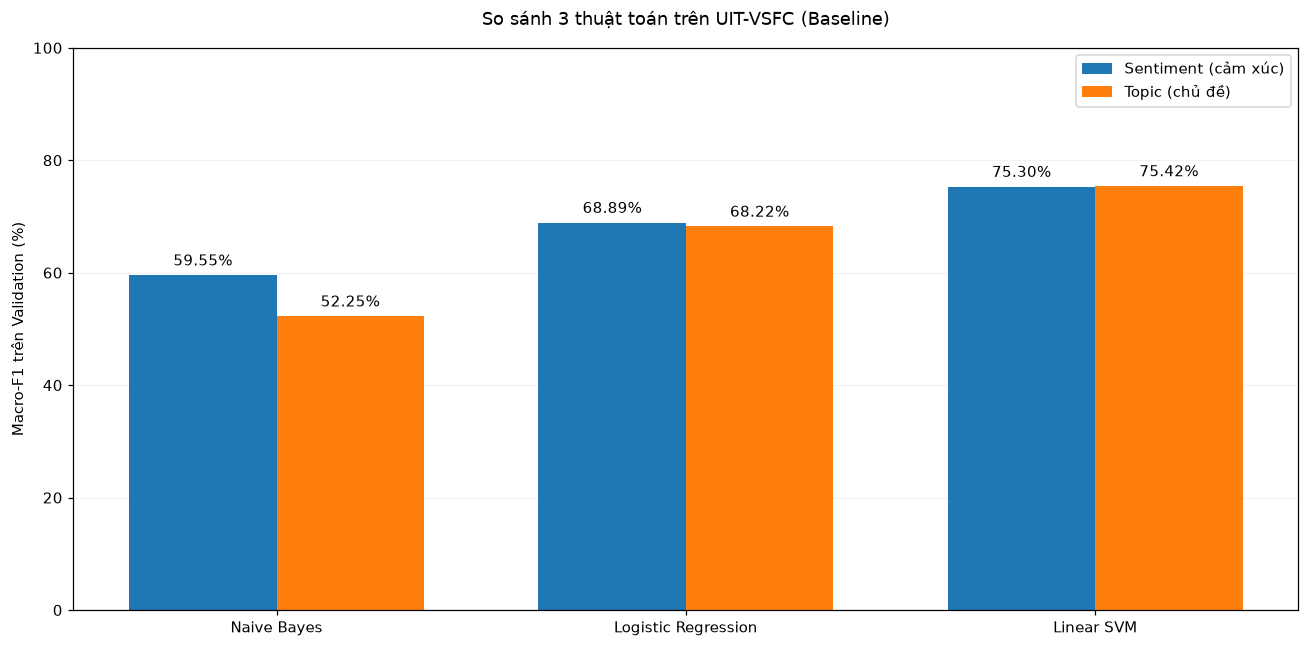

sentiment: chọn Linear SVM với validation Macro-F1 = 75.30%.
topic: chọn Linear SVM với validation Macro-F1 = 75.42%.
Đã hoàn thành báo cáo và biểu đồ Baseline.


In [10]:
summary = pd.DataFrame([
    {"task": task, "algorithm": name,
     "validation_macro_f1": results[task]["validation"][name]["macro_f1"],
     "validation_accuracy": results[task]["validation"][name]["accuracy"],
     "test_macro_f1": results[task]["test"][name]["macro_f1"],
     "test_accuracy": results[task]["test"][name]["accuracy"]}
    for task in LABELS for name in ALGORITHMS])
display(summary.round(6))
save_csv(summary, "summary.csv", index=False)
x = np.arange(len(ALGORITHMS))
fig, ax = plt.subplots(figsize=(12, 6))
for offset, task, label in ((-0.18, "sentiment", "Sentiment (cảm xúc)"),
                            (0.18, "topic", "Topic (chủ đề)")):
    values = [results[task]["validation"][name]["macro_f1"] * 100 for name in ALGORITHMS]
    bars = ax.bar(x + offset, values, 0.36, label=label)
    ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.set_xticks(x, [NAMES[name] for name in ALGORITHMS])
ax.set_ylim(0, 100)
ax.set_ylabel("Macro-F1 trên Validation (%)")
ax.set_title("So sánh 3 thuật toán trên UIT-VSFC (Baseline)", pad=15)
ax.legend()
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.15)
show_figure(fig, "validation_macro_f1.png")

for task in LABELS:
    winner = results[task]["selection"]["algorithm"]
    metric = results[task]["validation"][winner]
    print(f"{task}: chọn {NAMES[winner]} với validation Macro-F1 = {metric['macro_f1']:.2%}.")
print("Đã hoàn thành báo cáo và biểu đồ Baseline.")
if SAVE_OUTPUTS:
    print("File kết quả:", RUN)

## 6. Kiểm tra tính nhất quán của báo cáo

Kiểm tra đủ 6 pipeline (2 tác vụ × 3 thuật toán), số mẫu đánh giá,
tổng confusion matrix và phép lấy trung bình Macro-F1. Nếu còn các kết quả
`validation-demo-*` cũ cùng manifest, so sánh metric validation để xác nhận
mối liên hệ với biểu đồ Baseline trước đó. Không cần các thư mục cũ để chạy notebook.

In [11]:
assert len(summary) == 6
for task in LABELS:
    for split in ("validation", "test"):
        for name in ALGORITHMS:
            m = results[task][split][name]
            assert m["n_rows"] == len(frames[split])
            assert np.array(m["confusion_matrix"]).sum() == len(frames[split])
            assert np.isclose(np.mean([r["f1"] for r in m["per_class"]]), m["macro_f1"], atol=1e-12, rtol=0)
checked = 0
for old in sorted((ROOT / "outputs").glob("validation-demo-*")):
    for task in LABELS:
        path = old / f"{task}_validation.json"
        if not path.is_file():
            continue
        previous = json.loads(path.read_text(encoding="utf-8"))
        if previous.get("dataset_manifest_sha256") != manifest_hash:
            continue
        for name in ALGORITHMS:
            assert np.isclose(previous["validation"][name]["macro_f1"],
                              results[task]["validation"][name]["macro_f1"], atol=1e-12, rtol=0)
        checked += 1
print("Đạt: đủ 6 kết quả; số mẫu, confusion matrix và Macro-F1 nhất quán.")
print(f"Đã đối chiếu {checked} file kết quả validation cũ cùng manifest.")

Đạt: đủ 6 kết quả; số mẫu, confusion matrix và Macro-F1 nhất quán.
Đã đối chiếu 2 file kết quả validation cũ cùng manifest.
